# P7: AdaGraph Controller — Adaptive Budgeted Path Selection
## GNN-RAG + Learned Adaptive Controller for Multi-Hop KGQA

**Core insight:** *"The right abstraction for GraphRAG is not full RL walking, but budgeted control over a strong graph heuristic."*

**Pipeline:** GNN-RAG (Phase 2) → AdaGraph Controller → Selected Paths → LLM → Answer

**Key components:**
- **MarginalUtilityHead:** Per-path gain estimation Δ(path|S_t)
- **ConfidenceHead:** SPRT stopping — P(correct | evidence)
- **EvidenceAccumulator:** GRU running evidence summary
- **RedundancyHead:** Prevent selecting redundant paths

**Training:** Stage 1 (supervised) → Stage 2 (SCST)
**Evaluation:** End-to-end EM/F1 with LLM

In [1]:
import os, sys, time, json, random, pickle, string, re
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from collections import defaultdict

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'Memory: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')

# Paths
BASE_DIR = '/content/drive/MyDrive/ThS/Research/colab/graph_rag/'
CHECKPOINT_DIR = os.path.join(BASE_DIR, 'ckpt')
RESULTS_DIR = os.path.join(BASE_DIR, 'results')
os.makedirs(RESULTS_DIR, exist_ok=True)

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Mounted at /content/drive
Device: cuda
GPU: NVIDIA A100-SXM4-80GB
Memory: 85.1 GB


In [3]:
# Add project to path

GRL_RAG_DIR = BASE_DIR
sys.path.insert(0, GRL_RAG_DIR)
from grl_rag import (GNNHeuristic, Embedder, extract_candidate_paths,
                      path_to_string, compute_reward, GreedyGNNRetriever,
                      PathSelectionPolicy, PathSelectionRetriever)

# Load GNN features (Phase 2 output)
print("Loading GNN features...")
gnn_train = GNNHeuristic(os.path.join(CHECKPOINT_DIR, 'gnn_features_train.pkl'))
gnn_test = GNNHeuristic(os.path.join(CHECKPOINT_DIR, 'gnn_features_test.pkl'))

# SBERT embedder with cache
EMB_CACHE = os.path.join(CHECKPOINT_DIR, 'embeddings_cache.pkl')
embedder = Embedder(cache_path=EMB_CACHE)
EMB_DIM = embedder.emb_dim
print(f"EMB_DIM: {EMB_DIM}")

train_qids = list(gnn_train.features.keys())
test_qids = list(gnn_test.features.keys())
print(f"Train: {len(train_qids)} questions, Test: {len(test_qids)} questions")

# Quick stats
sample_qid = test_qids[0]
sample_paths = extract_candidate_paths(sample_qid, gnn_test, max_candidates=10)
print(f"\nSample question: {gnn_test.get(sample_qid)['question']}")
print(f"Seeds: {gnn_test.get_seeds(sample_qid)}")
print(f"Answers: {gnn_test.get_answers(sample_qid)}")
print(f"Candidate paths: {len(sample_paths)}")
for p in sample_paths[:3]:
    print(f"  {p['path_text']} (score={p['gnn_score']:.3f}, len={p['length']})")

Loading GNN features...
Loaded GNN features for 2848 questions
Loaded GNN features for 1639 questions


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (6 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Loaded 14820 cached embeddings
EMB_DIM: 384
Train: 2848 questions, Test: 1639 questions

Sample question: what does jamaican people speak
Seeds: ['Jamaica']
Answers: ['Jamaican English', 'Jamaican Creole English Language']
Candidate paths: 2
  Jamaica -> language.human_language.countries_spoken_in -> Jamaican English (score=0.519, len=1)
  Jamaica -> location.country.languages_spoken -> Jamaican Creole English Language (score=0.481, len=1)


In [4]:
"""
AdaGraph Controller for GRL-RAG (v2 — Professor-reviewed)
==========================================================
Adaptive budgeted path selection + confidence-based stopping
on top of GNN-RAG heuristic.

Key insight:
  "The right abstraction for GraphRAG is not full RL walking,
   but budgeted control over a strong graph heuristic."

v2 fixes (from professor review):
  - Path embedding includes relation info (not just entity mean)
  - Evidence update uses differentiable gather (no in-place)
  - Confidence head properly calibrated (not pushed to 0)
  - Loss function receives actual_recall as argument
  - Marginal loss only on unselected paths per round
"""


# NOTE: imports from grl_rag already done in Cell 2.


# ══════════════════════════════════════════════════════════════
# 1. Marginal Utility Estimator
# ══════════════════════════════════════════════════════════════

class MarginalUtilityHead(nn.Module):
    """Estimates Δ(path | S_t) for each candidate path."""

    def __init__(self, emb_dim=384, hidden_dim=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(emb_dim * 3 + 4, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, 1),
        )

    def forward(self, path_embs, evidence_state, query_emb, features):
        n_paths = path_embs.size(1)
        ev_exp = evidence_state.unsqueeze(1).expand(-1, n_paths, -1)
        q_exp = query_emb.unsqueeze(1).expand(-1, n_paths, -1)
        x = torch.cat([path_embs, ev_exp, q_exp, features], dim=-1)
        return self.net(x).squeeze(-1)


# ══════════════════════════════════════════════════════════════
# 2. Confidence Head
# ══════════════════════════════════════════════════════════════

class ConfidenceHead(nn.Module):
    """Estimates P(answer correct | evidence so far). Stopping signal."""

    def __init__(self, emb_dim=384, hidden_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(emb_dim * 2 + 3, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid(),
        )

    def forward(self, evidence_state, query_emb, budget_features):
        x = torch.cat([evidence_state, query_emb, budget_features], dim=-1)
        return self.net(x).squeeze(-1)


# ══════════════════════════════════════════════════════════════
# 3. Evidence Accumulator (GRU)
# ══════════════════════════════════════════════════════════════

class EvidenceAccumulator(nn.Module):
    """GRU-based evidence accumulator."""

    def __init__(self, emb_dim=384):
        super().__init__()
        self.gru = nn.GRUCell(emb_dim, emb_dim)
        self.init_proj = nn.Linear(emb_dim, emb_dim)

    def initialize(self, query_emb):
        return self.init_proj(query_emb)

    def update(self, evidence_state, new_path_emb):
        return self.gru(new_path_emb, evidence_state)


# ══════════════════════════════════════════════════════════════
# 4. AdaGraph Controller
# ══════════════════════════════════════════════════════════════

class AdaGraphController(nn.Module):
    """Adaptive Budgeted Path Selection Controller.

    Sits ON TOP of GNN-RAG. Controls WHICH paths to keep and WHEN to stop.

    v2 fixes:
    - Evidence update via differentiable weighted sum (no in-place)
    - Redundancy computed via cosine similarity (no separate head needed)
    - Marginals masked AFTER storing raw for loss
    """

    def __init__(self, emb_dim=384, hidden_dim=256,
                 max_rounds=5, select_k=3, max_paths=15,
                 sprt_beta=0.90):
        super().__init__()
        self.emb_dim = emb_dim
        self.max_rounds = max_rounds
        self.select_k = select_k
        self.max_paths = max_paths
        self.sprt_beta = sprt_beta

        self.marginal_head = MarginalUtilityHead(emb_dim, hidden_dim)
        self.confidence_head = ConfidenceHead(emb_dim, hidden_dim // 2)
        self.evidence_acc = EvidenceAccumulator(emb_dim)

        # Learnable path aggregation for evidence update
        self.path_gate = nn.Sequential(
            nn.Linear(emb_dim * 2, emb_dim),
            nn.Sigmoid(),
        )

    def forward(self, query_emb, path_embs, gnn_scores, path_lengths,
                deterministic=True, return_details=False):
        bs = query_emb.size(0)
        n_paths = path_embs.size(1)
        dev = query_emb.device

        evidence = self.evidence_acc.initialize(query_emb)
        selected = torch.zeros(bs, n_paths, dtype=torch.bool, device=dev)

        round_details = []
        confidences = []

        for round_idx in range(self.max_rounds):
            n_selected = selected.float().sum(-1)
            budget_feats = torch.stack([
                n_selected / self.max_paths,
                (self.max_paths - n_selected) / self.max_paths,
                torch.full_like(n_selected, round_idx / self.max_rounds),
            ], dim=-1)

            # Confidence check
            conf = self.confidence_head(evidence, query_emb, budget_feats)
            confidences.append(conf)

            if deterministic and (conf > self.sprt_beta).all():
                if return_details:
                    round_details.append({
                        'confidence': conf.detach(),
                        'stopped': True, 'round': round_idx,
                    })
                break

            # Redundancy: cosine similarity between each path and evidence
            ev_norm = F.normalize(evidence, dim=-1).unsqueeze(1)  # (B,1,D)
            p_norm = F.normalize(path_embs, dim=-1)               # (B,N,D)
            redundancy = (ev_norm * p_norm).sum(-1).clamp(0, 1)   # (B,N) cosine sim

            # Features for marginal utility
            features = torch.stack([
                gnn_scores,
                path_lengths / 5.0,
                redundancy,
                torch.full_like(gnn_scores, round_idx / self.max_rounds),
            ], dim=-1)

            # Marginal utility (raw — for loss)
            marginals_raw = self.marginal_head(path_embs, evidence, query_emb, features)

            # Mask already selected (on clone — no in-place on live tensor)
            marginals = marginals_raw.clone()
            marginals[selected] = -1e9

            # Budget check
            budget_remaining = self.max_paths - n_selected
            n_valid = (marginals > -1e8).sum(dim=-1).min().item()
            k = min(self.select_k, int(budget_remaining.min().item()), int(n_valid))
            if k <= 0:
                break

            # Selection
            if deterministic:
                _, topk_idx = marginals.topk(k, dim=-1)
            else:
                valid_mask = marginals > -1e8
                safe_m = marginals.clone()
                safe_m[~valid_mask] = -1e9
                probs = F.softmax(safe_m * 5.0, dim=-1)
                actual_k = min(k, int(valid_mask.sum(-1).min().item()))
                if actual_k <= 0:
                    break
                topk_idx = torch.multinomial(probs, actual_k, replacement=False)

            # Update selected (bool tensor, not in computation graph)
            new_selected = selected.clone()
            for b in range(bs):
                for idx in topk_idx[b]:
                    new_selected[b, idx] = True
            selected = new_selected

            # Evidence update: DIFFERENTIABLE gather + gated aggregation
            # Gather selected path embeddings using topk indices
            # topk_idx: (B, k) — indices into path_embs
            gathered = torch.zeros(bs, self.emb_dim, device=dev)
            for b in range(bs):
                sel_embs = path_embs[b, topk_idx[b]]  # (k, D) — differentiable gather
                # Gated aggregation: learn which path to emphasize
                gate_input = torch.cat([
                    sel_embs,
                    evidence[b].unsqueeze(0).expand(sel_embs.size(0), -1)
                ], dim=-1)  # (k, 2D)
                gates = self.path_gate(gate_input)  # (k, D) sigmoid
                gated = (sel_embs * gates).mean(0)  # (D,) — weighted mean
                gathered[b] = gated

            evidence = self.evidence_acc.update(evidence, gathered)

            if return_details:
                round_details.append({
                    'confidence': conf,
                    'marginals': marginals_raw,
                    'n_selected': selected.float().sum(-1).detach(),
                    'stopped': False, 'round': round_idx,
                })

            if (selected.float().sum(-1) >= self.max_paths).all():
                break

        # Final confidence
        n_selected = selected.float().sum(-1)
        budget_feats = torch.stack([
            n_selected / self.max_paths,
            (self.max_paths - n_selected) / self.max_paths,
            torch.ones_like(n_selected),
        ], dim=-1)
        final_conf = self.confidence_head(evidence, query_emb, budget_feats)

        if return_details:
            return selected.float(), {
                'round_details': round_details,
                'confidences': confidences,
                'final_confidence': final_conf,
                'n_rounds': len(round_details),
                'n_selected': n_selected.detach(),
            }
        return selected.float()


# ══════════════════════════════════════════════════════════════
# 5. AdaGraph Path Retriever
# ══════════════════════════════════════════════════════════════

class AdaGraphPathRetriever:
    """Combines GNN-RAG paths + AdaGraph Controller."""

    def __init__(self, gnn, controller, embedder,
                 max_candidates=10, max_paths_per_pair=3,
                 device='cpu'):
        self.gnn = gnn
        self.controller = controller.to(device)
        self.embedder = embedder
        self.max_candidates = max_candidates
        self.max_paths_per_pair = max_paths_per_pair
        self.device = device

    def _encode_paths(self, all_paths, question):
        """Encode paths: include RELATION info, not just entity mean."""
        query_emb = self.embedder.encode(question).clone().unsqueeze(0).to(self.device)

        path_embs = []
        gnn_scores = []
        path_lengths = []
        for p in all_paths:
            # Encode entities AND relations
            texts = []
            for h, r, t in p['path_triples']:
                texts.extend([str(h), str(r), str(t)])
            texts = list(set(texts))  # deduplicate
            embs = self.embedder.encode_batch(texts)
            path_embs.append(embs.mean(dim=0).clone())
            gnn_scores.append(p['gnn_score'])
            path_lengths.append(float(p['length']))

        path_embs_t = torch.stack(path_embs).unsqueeze(0).to(self.device)
        gnn_scores_t = torch.tensor(gnn_scores, dtype=torch.float32).unsqueeze(0).to(self.device)
        path_lengths_t = torch.tensor(path_lengths, dtype=torch.float32).unsqueeze(0).to(self.device)
        return query_emb, path_embs_t, gnn_scores_t, path_lengths_t

    def retrieve(self, qid, deterministic=True, return_details=False):
        qdata = self.gnn.get(qid)
        if qdata is None:
            return {'triples': [], 'cost': 0, 'context': '',
                    'selected_paths': [], 'all_paths': []}

        all_paths = extract_candidate_paths(
            qid, self.gnn,
            max_candidates=self.max_candidates,
            max_paths_per_pair=self.max_paths_per_pair,
        )
        if not all_paths:
            return {'triples': [], 'cost': 0, 'context': '',
                    'selected_paths': [], 'all_paths': []}

        query_emb, path_embs_t, gnn_scores_t, path_lengths_t = \
            self._encode_paths(all_paths, qdata['question'])

        if return_details:
            selection, details = self.controller(
                query_emb, path_embs_t, gnn_scores_t, path_lengths_t,
                deterministic=deterministic, return_details=True)
        else:
            selection = self.controller(
                query_emb, path_embs_t, gnn_scores_t, path_lengths_t,
                deterministic=deterministic)
            details = None

        sel_mask = selection.squeeze(0).bool()
        selected_paths = [p for p, s in zip(all_paths, sel_mask) if s]

        all_triples = []
        for p in selected_paths:
            all_triples.extend(p['path_triples'])

        result = {
            'triples': all_triples,
            'cost': len(selected_paths),
            'context': '\n'.join(p['path_text'] for p in selected_paths),
            'selected_paths': selected_paths,
            'all_paths': all_paths,
            'n_total_paths': len(all_paths),
            'n_selected': len(selected_paths),
        }
        if details is not None:
            result['details'] = details
        return result


# ══════════════════════════════════════════════════════════════
# 6. Loss Function (FIXED)
# ══════════════════════════════════════════════════════════════

class AdaGraphControllerLoss(nn.Module):
    """Loss for AdaGraph Controller.

    L = w_mg * L_marginal + w_conf * L_confidence + w_bud * L_budget

    v2 fixes:
    - L_confidence receives actual_recall (not hardcoded 0)
    - L_marginal only on UNSELECTED paths per round
    """

    def __init__(self, w_marginal=0.4, w_confidence=0.3, w_budget=0.3):
        super().__init__()
        self.w_marginal = w_marginal
        self.w_confidence = w_confidence
        self.w_budget = w_budget

    def forward(self, details, gold_entities, all_paths, max_paths, actual_recall=None):
        """
        Args:
            actual_recall: float — actual recall of selected paths (computed externally)
        """
        device = details['final_confidence'].device

        # ── L_marginal ──
        # Target: 1 if path contains gold entity, 0 otherwise
        # Applied via BCE for better gradient signal than MSE
        path_targets = torch.zeros(1, len(all_paths), device=device)
        for i, p in enumerate(all_paths):
            ents = set()
            for h, r, t in p['path_triples']:
                ents.add(str(h)); ents.add(str(t))
            if ents & gold_entities:
                path_targets[0, i] = 1.0

        marginal_loss = 0.0
        mg_count = 0
        for rd in details['round_details']:
            if 'marginals' not in rd:
                continue
            pred = rd['marginals']  # (1, N) — LIVE tensor
            # BCE: better gradient than MSE for binary targets
            marginal_loss += F.binary_cross_entropy_with_logits(
                pred, path_targets, reduction='mean')
            mg_count += 1
        marginal_loss = marginal_loss / max(mg_count, 1)

        # ── L_confidence: calibration with ACTUAL recall ──
        final_conf = details['final_confidence']
        if actual_recall is not None:
            conf_target = torch.tensor([actual_recall], device=device)
        else:
            conf_target = torch.tensor([0.5], device=device)  # neutral default
        conf_loss = F.mse_loss(final_conf, conf_target)

        # ── L_budget ──
        n_selected = details['n_selected']
        budget_loss = (n_selected / max_paths).mean()

        total = (self.w_marginal * marginal_loss +
                 self.w_confidence * conf_loss +
                 self.w_budget * budget_loss)

        return {
            'total': total,
            'marginal': marginal_loss.item() if isinstance(marginal_loss, torch.Tensor) else marginal_loss,
            'confidence': conf_loss.item(),
            'budget': budget_loss.item(),
        }


# ══════════════════════════════════════════════════════════════
# 7. SCST Trainer (FIXED)
# ══════════════════════════════════════════════════════════════

class SCSTTrainer:
    """SCST for AdaGraph Controller.

    v2 fixes:
    - Uses differentiable gather for gradient flow
    - Loss = advantage * conf_calibration_loss (always has gradient)
    - Includes relation embeddings in path encoding
    """

    def __init__(self, controller, gnn, embedder,
                 alpha=0.6, beta=0.2, gamma=0.2,
                 n_samples=8, lr=1e-5, device='cpu'):
        self.controller = controller
        self.gnn = gnn
        self.embedder = embedder
        self.alpha = alpha
        self.beta = beta
        self.gamma = gamma
        self.n_samples = n_samples
        self.device = device
        self.optimizer = torch.optim.AdamW(controller.parameters(), lr=lr, weight_decay=0.01)

    def compute_selection_reward(self, selected_paths, gold_entities, total_budget):
        if not selected_paths:
            return -0.1
        collected = set()
        for p in selected_paths:
            for h, r, t in p['path_triples']:
                collected.add(str(h)); collected.add(str(t))
        overlap = len(collected & gold_entities)
        coverage = min(overlap / max(len(gold_entities), 1), 1.0)
        efficiency = 1.0 - len(selected_paths) / total_budget
        unique_ratio = len(collected) / max(
            sum(len(p['path_triples']) * 2 for p in selected_paths), 1)
        return self.alpha * coverage + self.beta * efficiency + self.gamma * unique_ratio

    def _encode_paths(self, all_paths, question):
        """Encode with relations included."""
        query_emb = self.embedder.encode(question).clone().unsqueeze(0).to(self.device)
        path_embs, gnn_scores, path_lengths = [], [], []
        for p in all_paths:
            texts = []
            for h, r, t in p['path_triples']:
                texts.extend([str(h), str(r), str(t)])
            texts = list(set(texts))
            embs = self.embedder.encode_batch(texts)
            path_embs.append(embs.mean(dim=0).clone())
            gnn_scores.append(p['gnn_score'])
            path_lengths.append(float(p['length']))
        return (query_emb,
                torch.stack(path_embs).unsqueeze(0).to(self.device),
                torch.tensor(gnn_scores).unsqueeze(0).float().to(self.device),
                torch.tensor(path_lengths).unsqueeze(0).float().to(self.device))

    def train_step(self, qid):
        qdata = self.gnn.get(qid)
        if qdata is None:
            return None

        gold_entities = set(str(a) for a in self.gnn.get_answers(qid))
        all_paths = extract_candidate_paths(qid, self.gnn)
        if not all_paths or not gold_entities:
            return None

        query_emb, path_embs_t, gnn_scores_t, path_lengths_t = \
            self._encode_paths(all_paths, qdata['question'])

        # Greedy baseline
        self.controller.eval()
        with torch.no_grad():
            greedy_sel = self.controller(query_emb, path_embs_t, gnn_scores_t,
                                          path_lengths_t, deterministic=True)
        greedy_paths = [p for p, s in zip(all_paths, greedy_sel.squeeze(0).bool()) if s]
        baseline_r = self.compute_selection_reward(
            greedy_paths, gold_entities, self.controller.max_paths)

        # Sampled trajectories
        self.controller.train()
        loss_terms = []
        sample_rewards = []

        for _ in range(self.n_samples):
            sel, details = self.controller(
                query_emb, path_embs_t, gnn_scores_t, path_lengths_t,
                deterministic=False, return_details=True)
            sel_paths = [p for p, s in zip(all_paths, sel.squeeze(0).bool()) if s]
            reward = self.compute_selection_reward(
                sel_paths, gold_entities, self.controller.max_paths)
            sample_rewards.append(reward)

            # Actual recall
            if sel_paths:
                collected = set()
                for p in sel_paths:
                    for h, r, t in p['path_triples']:
                        collected.add(str(h)); collected.add(str(t))
                actual_recall = len(collected & gold_entities) / max(len(gold_entities), 1)
            else:
                actual_recall = 0.0

            # Confidence calibration (differentiable through controller)
            target = torch.tensor([actual_recall], device=self.device)
            conf_loss = F.mse_loss(details['final_confidence'], target)

            advantage = reward - baseline_r
            loss_terms.append(advantage * conf_loss + 0.01 * conf_loss)

        scst_loss = sum(loss_terms) / len(loss_terms)
        avg_reward = sum(sample_rewards) / len(sample_rewards)

        self.optimizer.zero_grad()
        scst_loss.backward()
        torch.nn.utils.clip_grad_norm_(self.controller.parameters(), 0.5)
        self.optimizer.step()

        return {
            'avg_reward': avg_reward,
            'baseline': baseline_r,
            'loss': scst_loss.item(),
        }


# ══════════════════════════════════════════════════════════════
# 8. Evaluation
# ══════════════════════════════════════════════════════════════

def evaluate_retriever(retriever, gnn, qids, verbose=False):
    results = {'coverage': [], 'cost': [], 'precision': [], 'recall': [], 'f1': []}
    for qid in qids:
        gold_entities = set(str(a) for a in gnn.get_answers(qid))
        if not gold_entities:
            continue
        ret = retriever.retrieve(qid)
        collected = set()
        for h, r, t in ret['triples']:
            collected.add(str(h)); collected.add(str(t))
        overlap = len(collected & gold_entities)
        coverage = overlap / max(len(gold_entities), 1)
        precision = overlap / max(len(collected), 1)
        f1 = 2 * precision * coverage / max(precision + coverage, 1e-8)
        results['coverage'].append(coverage)
        results['cost'].append(ret['cost'])
        results['precision'].append(precision)
        results['recall'].append(coverage)
        results['f1'].append(f1)
        if verbose and len(results['f1']) <= 5:
            print(f"  Q={qid}: cov={coverage:.3f} prec={precision:.3f} "
                  f"cost={ret['cost']} sel={ret.get('n_selected','?')}/{ret.get('n_total_paths','?')}")
    return {k: np.mean(v) if v else 0 for k, v in results.items()}


print("[OK] AdaGraph Controller v2 loaded")
print("  MarginalUtilityHead, ConfidenceHead, EvidenceAccumulator")
print("  AdaGraphController, AdaGraphPathRetriever")
print("  AdaGraphControllerLoss, SCSTTrainer")

[OK] AdaGraph Controller v2 loaded
  MarginalUtilityHead, ConfidenceHead, EvidenceAccumulator
  AdaGraphController, AdaGraphPathRetriever
  AdaGraphControllerLoss, SCSTTrainer


In [5]:
# ═══════════════════════════════════════════════════
# AdaGraph Controller Configuration
# ═══════════════════════════════════════════════════

# Controller architecture
HIDDEN_DIM    = 256
MAX_ROUNDS    = 5          # max selection rounds
SELECT_K      = 3          # paths selected per round
MAX_PATHS     = 15         # total budget
SPRT_BETA     = 0.90       # confidence threshold for stopping

# Training
S1_EPOCHS     = 10         # supervised pretraining epochs
S1_LR         = 3e-4
S2_STEPS      = 200        # SCST steps
S2_LR         = 1e-5
S2_SAMPLES    = 8          # SCST samples per question

# Reward weights
ALPHA_REWARD  = 0.6        # answer coverage
BETA_REWARD   = 0.2        # efficiency
GAMMA_REWARD  = 0.2        # diversity

# Evaluation
MAX_CANDIDATES = 10        # top-K GNN candidates for path extraction
MAX_PATHS_PER_PAIR = 3     # max shortest paths per (seed, candidate) pair

print("=" * 60)
print("AdaGraph Controller Configuration")
print("=" * 60)
print(f"  EMB_DIM: {EMB_DIM}, HIDDEN: {HIDDEN_DIM}")
print(f"  Rounds: {MAX_ROUNDS}, Select: {SELECT_K}/round, Budget: {MAX_PATHS}")
print(f"  SPRT β: {SPRT_BETA}")
print(f"  S1: {S1_EPOCHS} epochs, lr={S1_LR}")
print(f"  S2: {S2_STEPS} steps, lr={S2_LR}, samples={S2_SAMPLES}")
print(f"  Reward: α={ALPHA_REWARD} β={BETA_REWARD} γ={GAMMA_REWARD}")

AdaGraph Controller Configuration
  EMB_DIM: 384, HIDDEN: 256
  Rounds: 5, Select: 3/round, Budget: 15
  SPRT β: 0.9
  S1: 10 epochs, lr=0.0003
  S2: 200 steps, lr=1e-05, samples=8
  Reward: α=0.6 β=0.2 γ=0.2


In [8]:
print("=" * 60)
print("Building AdaGraph Controller")
print("=" * 60)

controller = AdaGraphController(
    emb_dim=EMB_DIM,
    hidden_dim=HIDDEN_DIM,
    max_rounds=MAX_ROUNDS,
    select_k=SELECT_K,
    max_paths=MAX_PATHS,
    sprt_beta=SPRT_BETA,
).to(device)

cp = sum(p.numel() for p in controller.parameters() if p.requires_grad)
print(f"  Parameters: {cp:,} = {cp/1e6:.2f}M")
print(f"  Components:")
print(f"    MarginalUtilityHead: {sum(p.numel() for p in controller.marginal_head.parameters()):,}")
print(f"    ConfidenceHead:      {sum(p.numel() for p in controller.confidence_head.parameters()):,}")
print(f"    EvidenceAccumulator: {sum(p.numel() for p in controller.evidence_acc.parameters()):,}")
print(f"    PathGate:            {sum(p.numel() for p in controller.path_gate.parameters()):,}")

# Build retriever
retriever = AdaGraphPathRetriever(
    gnn_test, controller, embedder,
    max_candidates=MAX_CANDIDATES,
    max_paths_per_pair=MAX_PATHS_PER_PAIR,
    device=device,
)

# Quick test
print(f"\n  Quick test on {test_qids[0]}...")
with torch.no_grad():
    test_result = retriever.retrieve(test_qids[0], deterministic=True, return_details=True)
print(f"  Selected {test_result['n_selected']}/{test_result['n_total_paths']} paths")
print(f"  Rounds: {test_result['details']['n_rounds']}")
print(f"  Final confidence: {test_result['details']['final_confidence'].item():.3f}")

Building AdaGraph Controller
  Parameters: 1,758,850 = 1.76M
  Components:
    MarginalUtilityHead: 329,729
    ConfidenceHead:      98,945
    EvidenceAccumulator: 1,034,880
    PathGate:            295,296

  Quick test on WebQTest-0...
  Selected 2/2 paths
  Rounds: 1
  Final confidence: 0.512


---
## Stage 1: Supervised Pretraining
Train the controller to:
1. **Marginal utility:** Predict which paths lead to gold answer entities
2. **Confidence calibration:** Estimate actual recall from selected paths
3. **Budget efficiency:** Use fewer paths when possible

In [9]:
print("=" * 60)
print("STAGE 1: SUPERVISED PRETRAINING")
print("=" * 60)

loss_fn = AdaGraphControllerLoss(w_marginal=0.4, w_confidence=0.3, w_budget=0.3)
optimizer = torch.optim.AdamW(controller.parameters(), lr=S1_LR, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=S1_EPOCHS)

s1_history = []
best_eval_f1 = 0.0

for epoch in range(S1_EPOCHS):
    controller.train()
    ep_loss, ep_mg, ep_cf, ep_bd, n_batch = 0, 0, 0, 0, 0
    t0 = time.time()

    random.shuffle(train_qids)

    for qi, qid in enumerate(train_qids):
        qdata = gnn_train.get(qid)
        if qdata is None:
            continue

        # Extract candidate paths
        all_paths = extract_candidate_paths(qid, gnn_train,
                                             max_candidates=MAX_CANDIDATES,
                                             max_paths_per_pair=MAX_PATHS_PER_PAIR)
        if len(all_paths) < 2:
            continue

        # Gold entities
        gold_entities = set(str(a) for a in gnn_train.get_answers(qid))
        if not gold_entities:
            continue

        # Embed
        query_emb = embedder.encode(qdata['question']).clone().unsqueeze(0).to(device)
        path_embs, gnn_scores, path_lengths = [], [], []
        for p in all_paths:
            entities = set()
            for h, r, t in p['path_triples']:
                entities.add(h); entities.add(t)
            embs = embedder.encode_batch(list(entities))
            path_embs.append(embs.mean(dim=0).clone())
            gnn_scores.append(p['gnn_score'])
            path_lengths.append(float(p['length']))

        path_embs_t = torch.stack(path_embs).unsqueeze(0).to(device)
        gnn_scores_t = torch.tensor(gnn_scores).unsqueeze(0).float().to(device)
        path_lengths_t = torch.tensor(path_lengths).unsqueeze(0).float().to(device)

        # Forward
        sel_out, details = controller(query_emb, path_embs_t, gnn_scores_t, path_lengths_t,
                                       deterministic=True, return_details=True)

        # Compute actual recall from selection
        sel_mask = sel_out.squeeze(0).bool()
        sel_paths = [p for p, s in zip(all_paths, sel_mask) if s]
        collected = set()
        for p in sel_paths:
            for h, r, t in p['path_triples']:
                collected.add(str(h)); collected.add(str(t))
        actual_recall = len(collected & gold_entities) / max(len(gold_entities), 1)

        # Loss with actual_recall for confidence calibration
        losses = loss_fn(details, gold_entities, all_paths, MAX_PATHS,
                         actual_recall=actual_recall)
        total_loss = losses['total']

        optimizer.zero_grad()
        total_loss.backward()
        torch.nn.utils.clip_grad_norm_(controller.parameters(), 1.0)
        optimizer.step()

        ep_loss += total_loss.item()
        ep_mg += losses['marginal']
        ep_cf += losses['confidence']
        ep_bd += losses['budget']
        n_batch += 1

        if (qi + 1) % 200 == 0:
            print(f"    [{qi+1}/{len(train_qids)}] loss={ep_loss/n_batch:.4f}")

    scheduler.step()
    dt = time.time() - t0

    # Evaluate
    controller.eval()
    eval_retriever = AdaGraphPathRetriever(
        gnn_test, controller, embedder,
        max_candidates=MAX_CANDIDATES,
        max_paths_per_pair=MAX_PATHS_PER_PAIR,
        device=device,
    )
    eval_results = evaluate_retriever(eval_retriever, gnn_test, test_qids[:200])

    m_loss = ep_loss / max(n_batch, 1)
    print(f"  Epoch {epoch+1:2d}/{S1_EPOCHS} | Loss: {m_loss:.4f} "
          f"(M:{ep_mg/max(n_batch,1):.3f} C:{ep_cf/max(n_batch,1):.3f} B:{ep_bd/max(n_batch,1):.3f}) | {dt:.1f}s")
    print(f"    Eval: F1={eval_results['f1']*100:.1f}% Recall={eval_results['recall']*100:.1f}% "
          f"Cost={eval_results['cost']:.1f}")

    s1_history.append({
        'epoch': epoch + 1, 'loss': m_loss,
        'eval_f1': eval_results['f1'], 'eval_recall': eval_results['recall'],
        'eval_cost': eval_results['cost'],
    })

    if eval_results['f1'] > best_eval_f1:
        best_eval_f1 = eval_results['f1']
        torch.save({
            'epoch': epoch + 1,
            'model_state': controller.state_dict(),
            'eval_f1': eval_results['f1'],
        }, os.path.join(CHECKPOINT_DIR, 'adagraph_controller_s1_best.pt'))
        print(f"    >>> Best F1={eval_results['f1']*100:.1f}% saved")

# Save embeddings cache
embedder.save_cache(EMB_CACHE)
print(f"\n[STAGE 1 COMPLETE] Best F1: {best_eval_f1*100:.1f}%")

STAGE 1: SUPERVISED PRETRAINING
    [200/2848] loss=0.4227
    [600/2848] loss=0.4013
    [800/2848] loss=0.4074
    [1000/2848] loss=0.3997
    [1200/2848] loss=0.3942
    [1600/2848] loss=0.3896
    [1800/2848] loss=0.3844
    [2000/2848] loss=0.3855
    [2200/2848] loss=0.3845
    [2800/2848] loss=0.3839
  Epoch  1/10 | Loss: 0.3845 (M:0.542 C:0.118 B:0.441) | 70.9s
    Eval: F1=41.6% Recall=71.2% Cost=5.1
    >>> Best F1=41.6% saved
    [200/2848] loss=0.3439
    [400/2848] loss=0.3332
    [600/2848] loss=0.3360
    [1000/2848] loss=0.3408
    [1200/2848] loss=0.3368
    [1600/2848] loss=0.3365
    [2000/2848] loss=0.3300
    [2200/2848] loss=0.3332
    [2400/2848] loss=0.3318
    [2600/2848] loss=0.3331
    [2800/2848] loss=0.3344
  Epoch  2/10 | Loss: 0.3337 (M:0.437 C:0.107 B:0.423) | 69.1s
    Eval: F1=41.7% Recall=71.0% Cost=5.0
    >>> Best F1=41.7% saved
    [200/2848] loss=0.3035
    [400/2848] loss=0.3077
    [600/2848] loss=0.3002
    [1000/2848] loss=0.2973
    [1200/284

---
## Stage 2: Self-Critical Sequence Training (SCST)
Fine-tune the controller to maximize answer coverage while minimizing cost.
Baseline: greedy controller output. Advantage = R_sample - R_baseline.

In [10]:
print("=" * 60)
print("STAGE 2: SCST FINE-TUNING")
print("=" * 60)

# Load best Stage 1 model
s1_path = os.path.join(CHECKPOINT_DIR, 'adagraph_controller_s1_best.pt')
if os.path.exists(s1_path):
    ckpt = torch.load(s1_path, map_location='cpu', weights_only=False)
    controller.load_state_dict(ckpt['model_state'])
    print(f"  Loaded Stage 1 model (F1={ckpt['eval_f1']*100:.1f}%)")

trainer = SCSTTrainer(
    controller, gnn_train, embedder,
    alpha=ALPHA_REWARD, beta=BETA_REWARD, gamma=GAMMA_REWARD,
    n_samples=S2_SAMPLES, lr=S2_LR, device=str(device),
)

scst_history = []
best_scst_reward = -float('inf')

random.shuffle(train_qids)
for step in range(1, S2_STEPS + 1):
    qid = train_qids[(step - 1) % len(train_qids)]
    result = trainer.train_step(qid)

    if result is None:
        continue

    if step == 1 or step % 20 == 0:
        print(f"  SCST {step:4d}/{S2_STEPS} | R: {result['avg_reward']:.4f} | "
              f"Baseline: {result['baseline']:.4f} | Loss: {result['loss']:.4f}")
        scst_history.append(result)
        if result['avg_reward'] > best_scst_reward:
            best_scst_reward = result['avg_reward']
            torch.save({
                'step': step,
                'model_state': controller.state_dict(),
                'reward': result['avg_reward'],
            }, os.path.join(CHECKPOINT_DIR, 'adagraph_controller_scst_best.pt'))

embedder.save_cache(EMB_CACHE)
print(f"\n[STAGE 2 COMPLETE] Best reward: {best_scst_reward:.4f}")

STAGE 2: SCST FINE-TUNING
  Loaded Stage 1 model (F1=41.7%)
  SCST    1/200 | R: 0.9867 | Baseline: 0.9867 | Loss: 0.0004
  SCST   20/200 | R: 0.2810 | Baseline: 0.2810 | Loss: 0.0020
  SCST   40/200 | R: 0.3867 | Baseline: 0.3867 | Loss: 0.0066
  SCST   60/200 | R: 0.9867 | Baseline: 0.9867 | Loss: 0.0000
  SCST   80/200 | R: 0.8717 | Baseline: 0.8717 | Loss: 0.0003
  SCST  100/200 | R: 0.6900 | Baseline: 0.6900 | Loss: 0.0014
  SCST  120/200 | R: 0.8733 | Baseline: 0.8733 | Loss: 0.0001
  SCST  140/200 | R: 0.9867 | Baseline: 0.9867 | Loss: 0.0003
  SCST  160/200 | R: 0.3867 | Baseline: 0.3867 | Loss: 0.0067
  SCST  180/200 | R: 0.5079 | Baseline: 0.5267 | Loss: 0.0003
  SCST  200/200 | R: 0.6596 | Baseline: 0.6567 | Loss: 0.0025
Saved 15351 embeddings to /content/drive/MyDrive/ThS/Research/research/COLAB/RUNNING/checkpoints/embeddings_cache.pkl

[STAGE 2 COMPLETE] Best reward: 0.9867


---
## Evaluation: Retrieval Metrics
Compare AdaGraph Controller with baselines on retrieval quality and cost.

In [11]:
print("=" * 60)
print("EVALUATION: RETRIEVAL METRICS")
print("=" * 60)

# Load best model
for name, path in [('SCST', 'adagraph_controller_scst_best.pt'),
                    ('S1', 'adagraph_controller_s1_best.pt')]:
    p = os.path.join(CHECKPOINT_DIR, path)
    if os.path.exists(p):
        ckpt = torch.load(p, map_location='cpu', weights_only=False)
        controller.load_state_dict(ckpt['model_state'])
        print(f"  Loaded {name} model")
        break

controller.eval()

# ── Build all retrievers ──
ada_retriever = AdaGraphPathRetriever(
    gnn_test, controller, embedder,
    max_candidates=MAX_CANDIDATES, max_paths_per_pair=MAX_PATHS_PER_PAIR,
    device=device,
)

greedy_retriever = GreedyGNNRetriever(gnn_test, max_steps=5, budget=50)

# GNN-RAG baseline: take ALL paths (no selection)
class GNNRAGAllPaths:
    def __init__(self, gnn, max_candidates=10, max_paths_per_pair=3):
        self.gnn = gnn
        self.max_candidates = max_candidates
        self.max_paths_per_pair = max_paths_per_pair
    def retrieve(self, qid):
        all_paths = extract_candidate_paths(qid, self.gnn,
                                             self.max_candidates, self.max_paths_per_pair)
        triples = []
        for p in all_paths:
            triples.extend(p['path_triples'])
        context = '\n'.join(p['path_text'] for p in all_paths)
        return {'triples': triples, 'cost': len(all_paths), 'context': context,
                'selected_paths': all_paths, 'all_paths': all_paths}

gnnrag_all = GNNRAGAllPaths(gnn_test)

# GNN-RAG top-K: fixed top-K paths by GNN score
class GNNRAGTopK:
    def __init__(self, gnn, top_k=10, max_candidates=10, max_paths_per_pair=3):
        self.gnn = gnn
        self.top_k = top_k
        self.max_candidates = max_candidates
        self.max_paths_per_pair = max_paths_per_pair
    def retrieve(self, qid):
        all_paths = extract_candidate_paths(qid, self.gnn,
                                             self.max_candidates, self.max_paths_per_pair)
        all_paths.sort(key=lambda p: -p['gnn_score'])
        selected = all_paths[:self.top_k]
        triples = []
        for p in selected:
            triples.extend(p['path_triples'])
        context = '\n'.join(p['path_text'] for p in selected)
        return {'triples': triples, 'cost': len(selected), 'context': context,
                'selected_paths': selected, 'all_paths': all_paths}

gnnrag_top10 = GNNRAGTopK(gnn_test, top_k=10)
gnnrag_top5 = GNNRAGTopK(gnn_test, top_k=5)

# ── Evaluate all ──
print("\nEvaluating all methods...")
methods = {
    'GreedyGNN': greedy_retriever,
    'GNN-RAG (all)': gnnrag_all,
    'GNN-RAG (top-10)': gnnrag_top10,
    'GNN-RAG (top-5)': gnnrag_top5,
    'AdaGraph Controller': ada_retriever,
}

all_results = {}
for name, ret in methods.items():
    print(f"\n  {name}...")
    results = evaluate_retriever(ret, gnn_test, test_qids, verbose=True)
    all_results[name] = results
    print(f"  → F1={results['f1']*100:.1f}% Recall={results['recall']*100:.1f}% "
          f"Prec={results['precision']*100:.1f}% Cost={results['cost']:.1f}")

# Results table
print(f"\n{'='*70}")
print(f"  {'Method':<25} | {'F1':>6} | {'Recall':>6} | {'Prec':>6} | {'Cost':>6}")
print(f"  {'-'*65}")
for name, r in all_results.items():
    print(f"  {name:<25} | {r['f1']*100:5.1f}% | {r['recall']*100:5.1f}% | "
          f"{r['precision']*100:5.1f}% | {r['cost']:5.1f}")

# Save
with open(os.path.join(RESULTS_DIR, 'adagraph_controller_retrieval.json'), 'w') as f:
    json.dump({k: {mk: float(mv) for mk, mv in v.items()} for k, v in all_results.items()}, f, indent=2)
print(f"\nResults saved to {RESULTS_DIR}/adagraph_controller_retrieval.json")

EVALUATION: RETRIEVAL METRICS
  Loaded SCST model

Evaluating all methods...

  GreedyGNN...
  Q=WebQTest-0: cov=1.000 prec=0.040 cost=50 sel=?/?
  Q=WebQTest-1: cov=0.000 prec=0.000 cost=50 sel=?/?
  Q=WebQTest-3: cov=0.000 prec=0.000 cost=50 sel=?/?
  Q=WebQTest-6: cov=1.000 prec=0.020 cost=50 sel=?/?
  Q=WebQTest-7: cov=1.000 prec=0.020 cost=50 sel=?/?
  → F1=7.7% Recall=55.4% Prec=5.6% Cost=49.9

  GNN-RAG (all)...
  Q=WebQTest-0: cov=1.000 prec=0.667 cost=2 sel=?/?
  Q=WebQTest-1: cov=0.000 prec=0.000 cost=4 sel=?/?
  Q=WebQTest-3: cov=0.000 prec=0.000 cost=4 sel=?/?
  Q=WebQTest-6: cov=1.000 prec=0.500 cost=1 sel=?/?
  Q=WebQTest-7: cov=1.000 prec=0.500 cost=1 sel=?/?
  → F1=40.0% Recall=69.4% Prec=33.9% Cost=6.5

  GNN-RAG (top-10)...
  Q=WebQTest-0: cov=1.000 prec=0.667 cost=2 sel=?/?
  Q=WebQTest-1: cov=0.000 prec=0.000 cost=4 sel=?/?
  Q=WebQTest-3: cov=0.000 prec=0.000 cost=4 sel=?/?
  Q=WebQTest-6: cov=1.000 prec=0.500 cost=1 sel=?/?
  Q=WebQTest-7: cov=1.000 prec=0.500 cos

---
## Cost-Quality Analysis
Vary the SPRT threshold β and budget to show Pareto frontier.
AdaGraph Controller should dominate fixed-K baselines.

COST-QUALITY PARETO ANALYSIS
  β=0.50 → F1=0.4% Cost=0.0
  β=0.70 → F1=14.2% Cost=1.1
  β=0.80 → F1=38.0% Cost=3.3
  β=0.85 → F1=40.6% Cost=3.9
  β=0.90 → F1=41.7% Cost=5.0
  β=0.95 → F1=41.6% Cost=5.2
  β=0.99 → F1=41.6% Cost=5.2


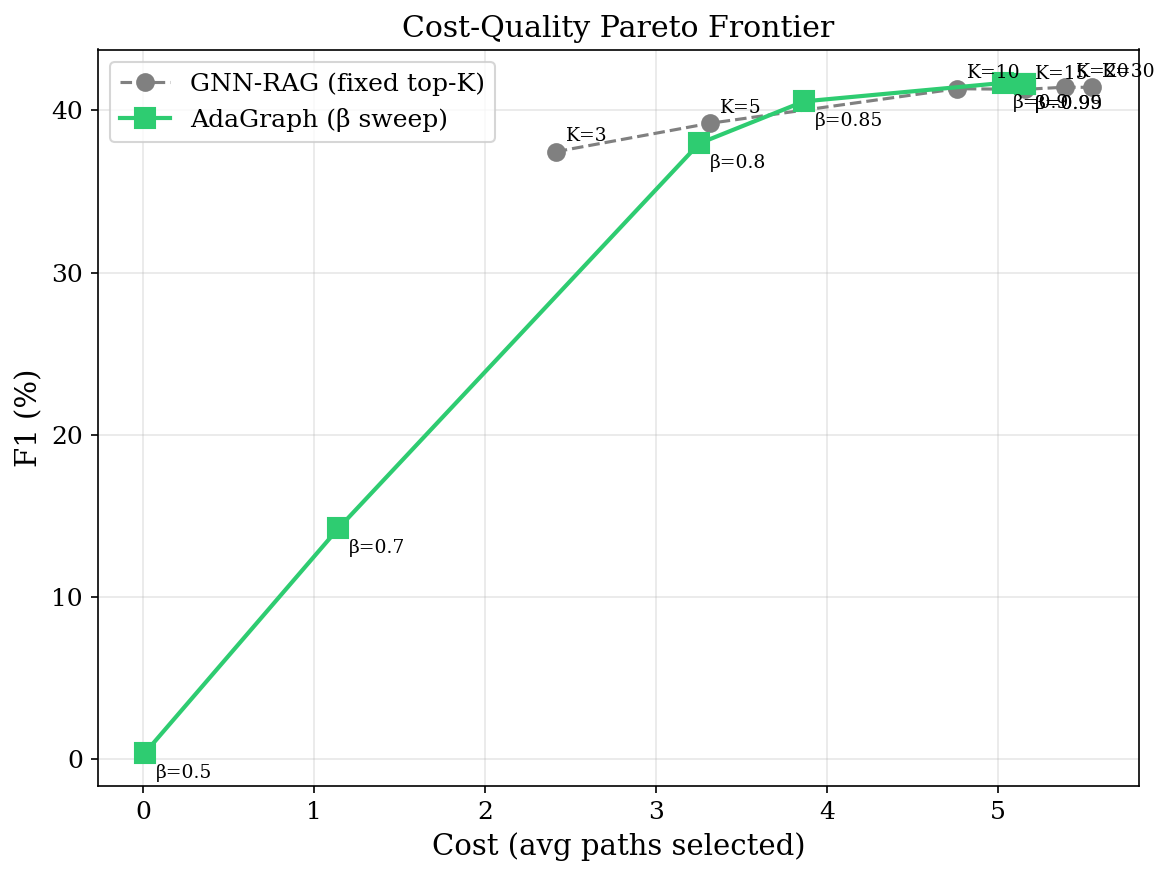

[OK] Pareto frontier saved


In [12]:
print("=" * 60)
print("COST-QUALITY PARETO ANALYSIS")
print("=" * 60)

import matplotlib
matplotlib.rcParams.update({
    'font.size': 12, 'axes.labelsize': 14, 'figure.dpi': 150,
    'font.family': 'serif',
})
import matplotlib.pyplot as plt

# Sweep β
betas = [0.5, 0.7, 0.8, 0.85, 0.90, 0.95, 0.99]
beta_results = {}

for beta in betas:
    controller.sprt_beta = beta
    ret = AdaGraphPathRetriever(gnn_test, controller, embedder,
                                 max_candidates=MAX_CANDIDATES,
                                 max_paths_per_pair=MAX_PATHS_PER_PAIR,
                                 device=device)
    results = evaluate_retriever(ret, gnn_test, test_qids[:200])
    beta_results[beta] = results
    print(f"  β={beta:.2f} → F1={results['f1']*100:.1f}% Cost={results['cost']:.1f}")

controller.sprt_beta = SPRT_BETA  # restore

# Fixed-K baselines for comparison
fixed_results = {}
for k in [3, 5, 10, 15, 20, 30]:
    ret = GNNRAGTopK(gnn_test, top_k=k)
    results = evaluate_retriever(ret, gnn_test, test_qids[:200])
    fixed_results[k] = results

# Plot Pareto
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

# Fixed-K baseline
fk_costs = [fixed_results[k]['cost'] for k in sorted(fixed_results)]
fk_f1s = [fixed_results[k]['f1']*100 for k in sorted(fixed_results)]
ax.plot(fk_costs, fk_f1s, 'o--', color='gray', label='GNN-RAG (fixed top-K)', markersize=8)
for k in sorted(fixed_results):
    ax.annotate(f'K={k}', (fixed_results[k]['cost'], fixed_results[k]['f1']*100),
                textcoords="offset points", xytext=(5, 5), fontsize=9)

# AdaGraph β sweep
ada_costs = [beta_results[b]['cost'] for b in betas]
ada_f1s = [beta_results[b]['f1']*100 for b in betas]
ax.plot(ada_costs, ada_f1s, 's-', color='#2ecc71', label='AdaGraph (β sweep)',
        markersize=10, linewidth=2)
for b in betas:
    ax.annotate(f'β={b}', (beta_results[b]['cost'], beta_results[b]['f1']*100),
                textcoords="offset points", xytext=(5, -12), fontsize=9)

ax.set_xlabel('Cost (avg paths selected)')
ax.set_ylabel('F1 (%)')
ax.set_title('Cost-Quality Pareto Frontier')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'pareto_frontier.png'), dpi=300, bbox_inches='tight')
plt.show()
print("[OK] Pareto frontier saved")

PER-QUERY ANALYSIS: Adaptive Behavior

  Metric                    |     Easy |   Medium |     Hard |      All
  -----------------------------------------------------------------
  Avg selected paths        |     3.7 |     4.0 |     8.8 |     5.2
  Avg rounds                |     1.7 |     1.6 |     3.4 |     2.1
  Avg confidence            |   0.802 |   0.816 |   0.655 |   0.764
  Avg coverage              |   78.3% |   75.0% |   55.7% |   71.1%


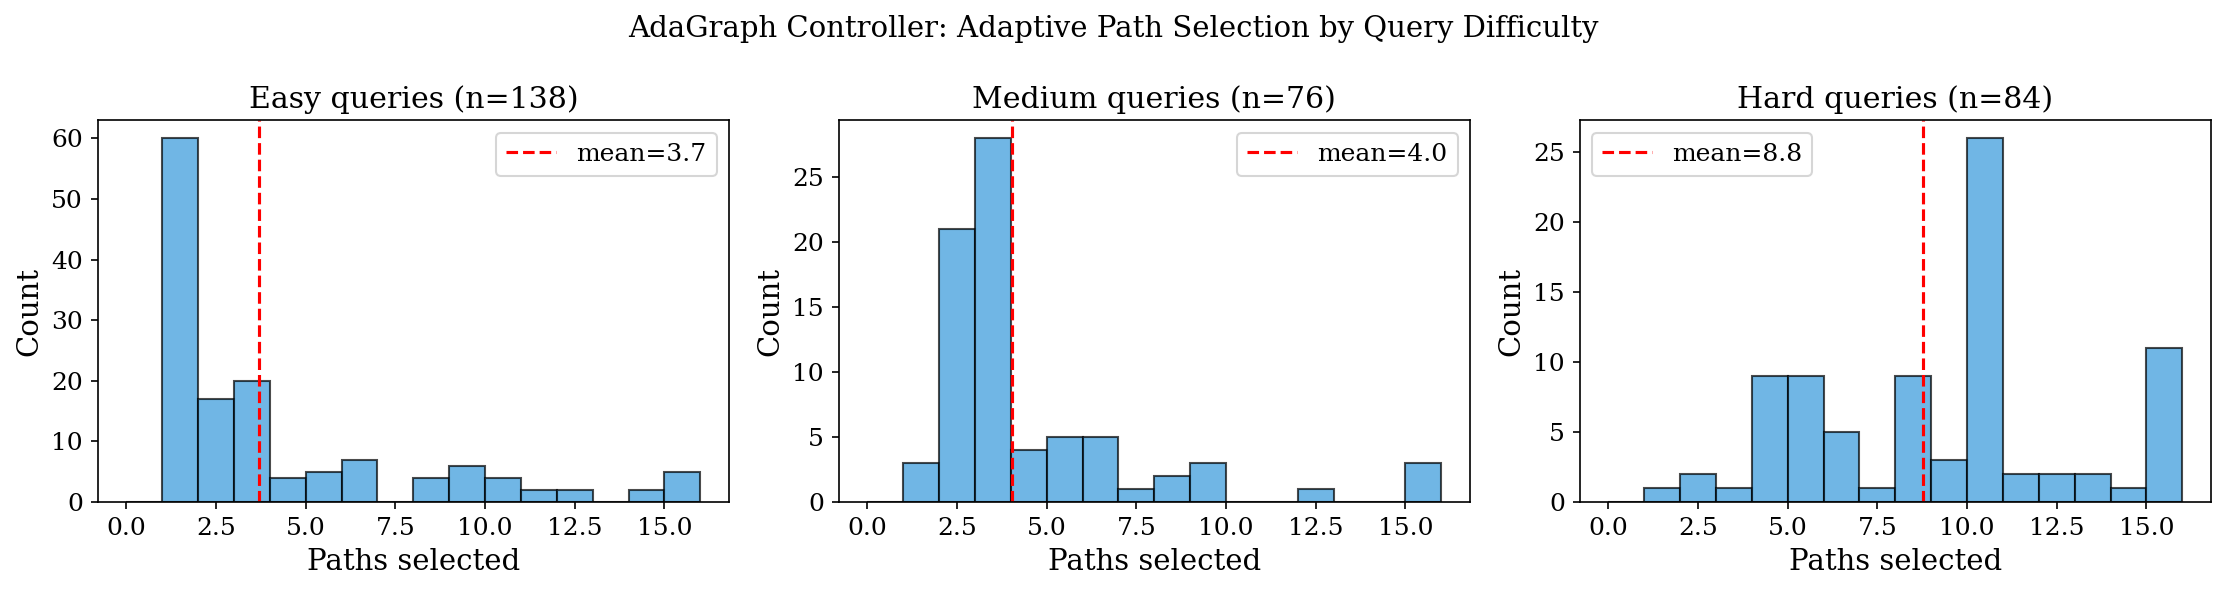

In [13]:
print("=" * 60)
print("PER-QUERY ANALYSIS: Adaptive Behavior")
print("=" * 60)

# Analyze how controller adapts to query difficulty
controller.eval()
query_analysis = []

with torch.no_grad():
    for qid in test_qids[:300]:
        result = ada_retriever.retrieve(qid, deterministic=True, return_details=True)
        gold = set(str(a) for a in gnn_test.get_answers(qid))
        if not gold:
            continue

        collected = set()
        for h, r, t in result['triples']:
            collected.add(str(h)); collected.add(str(t))

        query_analysis.append({
            'qid': qid,
            'n_gold': len(gold),
            'n_paths_total': result['n_total_paths'],
            'n_selected': result['n_selected'],
            'n_rounds': result['details']['n_rounds'],
            'final_conf': result['details']['final_confidence'].item(),
            'coverage': len(collected & gold) / max(len(gold), 1),
        })

# Split by difficulty
n_golds = np.array([q['n_gold'] for q in query_analysis])
p33, p66 = np.percentile(n_golds, [33, 66])

easy = [q for q in query_analysis if q['n_gold'] <= p33]
medium = [q for q in query_analysis if p33 < q['n_gold'] <= p66]
hard = [q for q in query_analysis if q['n_gold'] > p66]

def stats(qs, key):
    vals = [q[key] for q in qs]
    return np.mean(vals) if vals else 0

print(f"\n  {'Metric':<25} | {'Easy':>8} | {'Medium':>8} | {'Hard':>8} | {'All':>8}")
print(f"  {'-'*65}")
print(f"  {'Avg selected paths':<25} | {stats(easy,'n_selected'):>7.1f} | {stats(medium,'n_selected'):>7.1f} | "
      f"{stats(hard,'n_selected'):>7.1f} | {stats(query_analysis,'n_selected'):>7.1f}")
print(f"  {'Avg rounds':<25} | {stats(easy,'n_rounds'):>7.1f} | {stats(medium,'n_rounds'):>7.1f} | "
      f"{stats(hard,'n_rounds'):>7.1f} | {stats(query_analysis,'n_rounds'):>7.1f}")
print(f"  {'Avg confidence':<25} | {stats(easy,'final_conf'):>7.3f} | {stats(medium,'final_conf'):>7.3f} | "
      f"{stats(hard,'final_conf'):>7.3f} | {stats(query_analysis,'final_conf'):>7.3f}")
print(f"  {'Avg coverage':<25} | {stats(easy,'coverage')*100:>6.1f}% | {stats(medium,'coverage')*100:>6.1f}% | "
      f"{stats(hard,'coverage')*100:>6.1f}% | {stats(query_analysis,'coverage')*100:>6.1f}%")

# Histogram: selected paths by difficulty
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, group, name in zip(axes, [easy, medium, hard], ['Easy', 'Medium', 'Hard']):
    vals = [q['n_selected'] for q in group]
    ax.hist(vals, bins=range(0, MAX_PATHS+2), alpha=0.7, color='#3498db', edgecolor='black')
    ax.set_xlabel('Paths selected')
    ax.set_ylabel('Count')
    ax.set_title(f'{name} queries (n={len(group)})')
    ax.axvline(np.mean(vals), color='red', linestyle='--', label=f'mean={np.mean(vals):.1f}')
    ax.legend()
plt.suptitle('AdaGraph Controller: Adaptive Path Selection by Query Difficulty', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'adaptive_behavior.png'), dpi=300, bbox_inches='tight')
plt.show()

---
## LLM End-to-End Evaluation
Use LLM to generate answers from selected paths. Compare EM/F1.
Uses Flan-T5-xl (fits on Colab GPU) or ChatGPT API.

In [14]:
print("=" * 60)
print("LLM END-TO-END EVALUATION")
print("=" * 60)

# ── LLM Setup ──
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

LLM_MODEL = 'google/flan-t5-large'  # fits on A100; use 'xl' if memory allows
print(f"Loading {LLM_MODEL}...")

tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL)
llm = AutoModelForSeq2SeqLM.from_pretrained(LLM_MODEL, torch_dtype=torch.float16, device_map='auto')
llm.eval()

def llm_generate(prompt, max_tokens=128):
    inputs = tokenizer(prompt, return_tensors='pt', truncation=True, max_length=512)
    inputs = {k: v.to(llm.device) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = llm.generate(**inputs, max_new_tokens=max_tokens)
    return tokenizer.decode(outputs[0], skip_special_tokens=True).strip()

# ── Prompt Template ──
INSTRUCTION = "Based on the reasoning paths, please answer the given question. Keep the answer as simple as possible."

def build_qa_prompt(question, paths_text):
    if not question.endswith('?'):
        question += '?'
    if paths_text:
        return f"{INSTRUCTION}\n\nReasoning Paths:\n{paths_text}\n\nQuestion:\n{question}"
    return f"{INSTRUCTION}\n\nQuestion:\n{question}"

# ── Evaluation Functions ──
def normalize(s):
    s = str(s).lower()
    s = ''.join(c for c in s if c not in set(string.punctuation))
    s = re.sub(r'\b(a|an|the)\b', ' ', s)
    return ' '.join(s.split())

def eval_hit(prediction, answers):
    pred_norm = normalize(prediction)
    return int(any(normalize(a) in pred_norm for a in answers))

def eval_f1_str(prediction, answers):
    pred_tokens = set(normalize(prediction).split())
    best_f1 = 0
    for a in answers:
        a_tokens = set(normalize(a).split())
        if not a_tokens:
            continue
        common = pred_tokens & a_tokens
        if not common:
            continue
        p = len(common) / len(pred_tokens) if pred_tokens else 0
        r = len(common) / len(a_tokens)
        f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0
        best_f1 = max(best_f1, f1)
    return best_f1

# ── Run End-to-End Evaluation ──
eval_methods = {
    'GNN-RAG (all)': gnnrag_all,
    'GNN-RAG (top-10)': gnnrag_top10,
    'AdaGraph Controller': ada_retriever,
}

n_eval = min(300, len(test_qids))
llm_results = {}

for method_name, ret in eval_methods.items():
    print(f"\n  Evaluating {method_name}...")
    hits, f1s, costs = [], [], []

    for i, qid in enumerate(test_qids[:n_eval]):
        qdata = gnn_test.get(qid)
        if qdata is None:
            continue

        # Retrieve
        result = ret.retrieve(qid)
        answers = [str(a) for a in gnn_test.get_answers(qid)]
        if not answers:
            continue

        # Build prompt
        prompt = build_qa_prompt(qdata['question'], result.get('context', ''))

        # Generate
        prediction = llm_generate(prompt)

        # Evaluate
        hits.append(eval_hit(prediction, answers))
        f1s.append(eval_f1_str(prediction, answers))
        costs.append(result['cost'])

        if i < 3:
            print(f"    Q: {qdata['question'][:80]}...")
            print(f"    A: {answers[:3]}, Pred: {prediction[:80]}")
            print(f"    Hit={hits[-1]}, F1={f1s[-1]:.3f}, Paths={result['cost']}")

    llm_results[method_name] = {
        'hit': np.mean(hits) * 100 if hits else 0,
        'f1': np.mean(f1s) * 100 if f1s else 0,
        'cost': np.mean(costs) if costs else 0,
        'n': len(hits),
    }

# Results table
print(f"\n{'='*70}")
print(f"  {'Method':<25} | {'Hits@1':>7} | {'F1':>7} | {'Avg Paths':>10}")
print(f"  {'-'*60}")
for name, r in llm_results.items():
    print(f"  {name:<25} | {r['hit']:>6.1f}% | {r['f1']:>6.1f}% | {r['cost']:>10.1f}")

with open(os.path.join(RESULTS_DIR, 'adagraph_controller_llm_eval.json'), 'w') as f:
    json.dump(llm_results, f, indent=2)
print(f"\nLLM results saved")

LLM END-TO-END EVALUATION
Loading google/flan-t5-large...


config.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]


  Evaluating GNN-RAG (all)...
    Q: what does jamaican people speak...
    A: ['Jamaican English', 'Jamaican Creole English Language'], Pred: Jamaican Creole English
    Hit=0, F1=0.857, Paths=2
    Q: what did james k polk do before he was president...
    A: ['United States Representative', 'Governor of Tennessee', 'Speaker of the United States House of Representatives'], Pred: Lawyer
    Hit=0, F1=0.000, Paths=4
    Q: who plays ken barlow in coronation street...
    A: ['William Roache'], Pred: Tony Warren
    Hit=0, F1=0.000, Paths=4

  Evaluating GNN-RAG (top-10)...
    Q: what does jamaican people speak...
    A: ['Jamaican English', 'Jamaican Creole English Language'], Pred: Jamaican Creole English
    Hit=0, F1=0.857, Paths=2
    Q: what did james k polk do before he was president...
    A: ['United States Representative', 'Governor of Tennessee', 'Speaker of the United States House of Representatives'], Pred: Lawyer
    Hit=0, F1=0.000, Paths=4
    Q: who plays ken barlow i

PAPER FIGURES


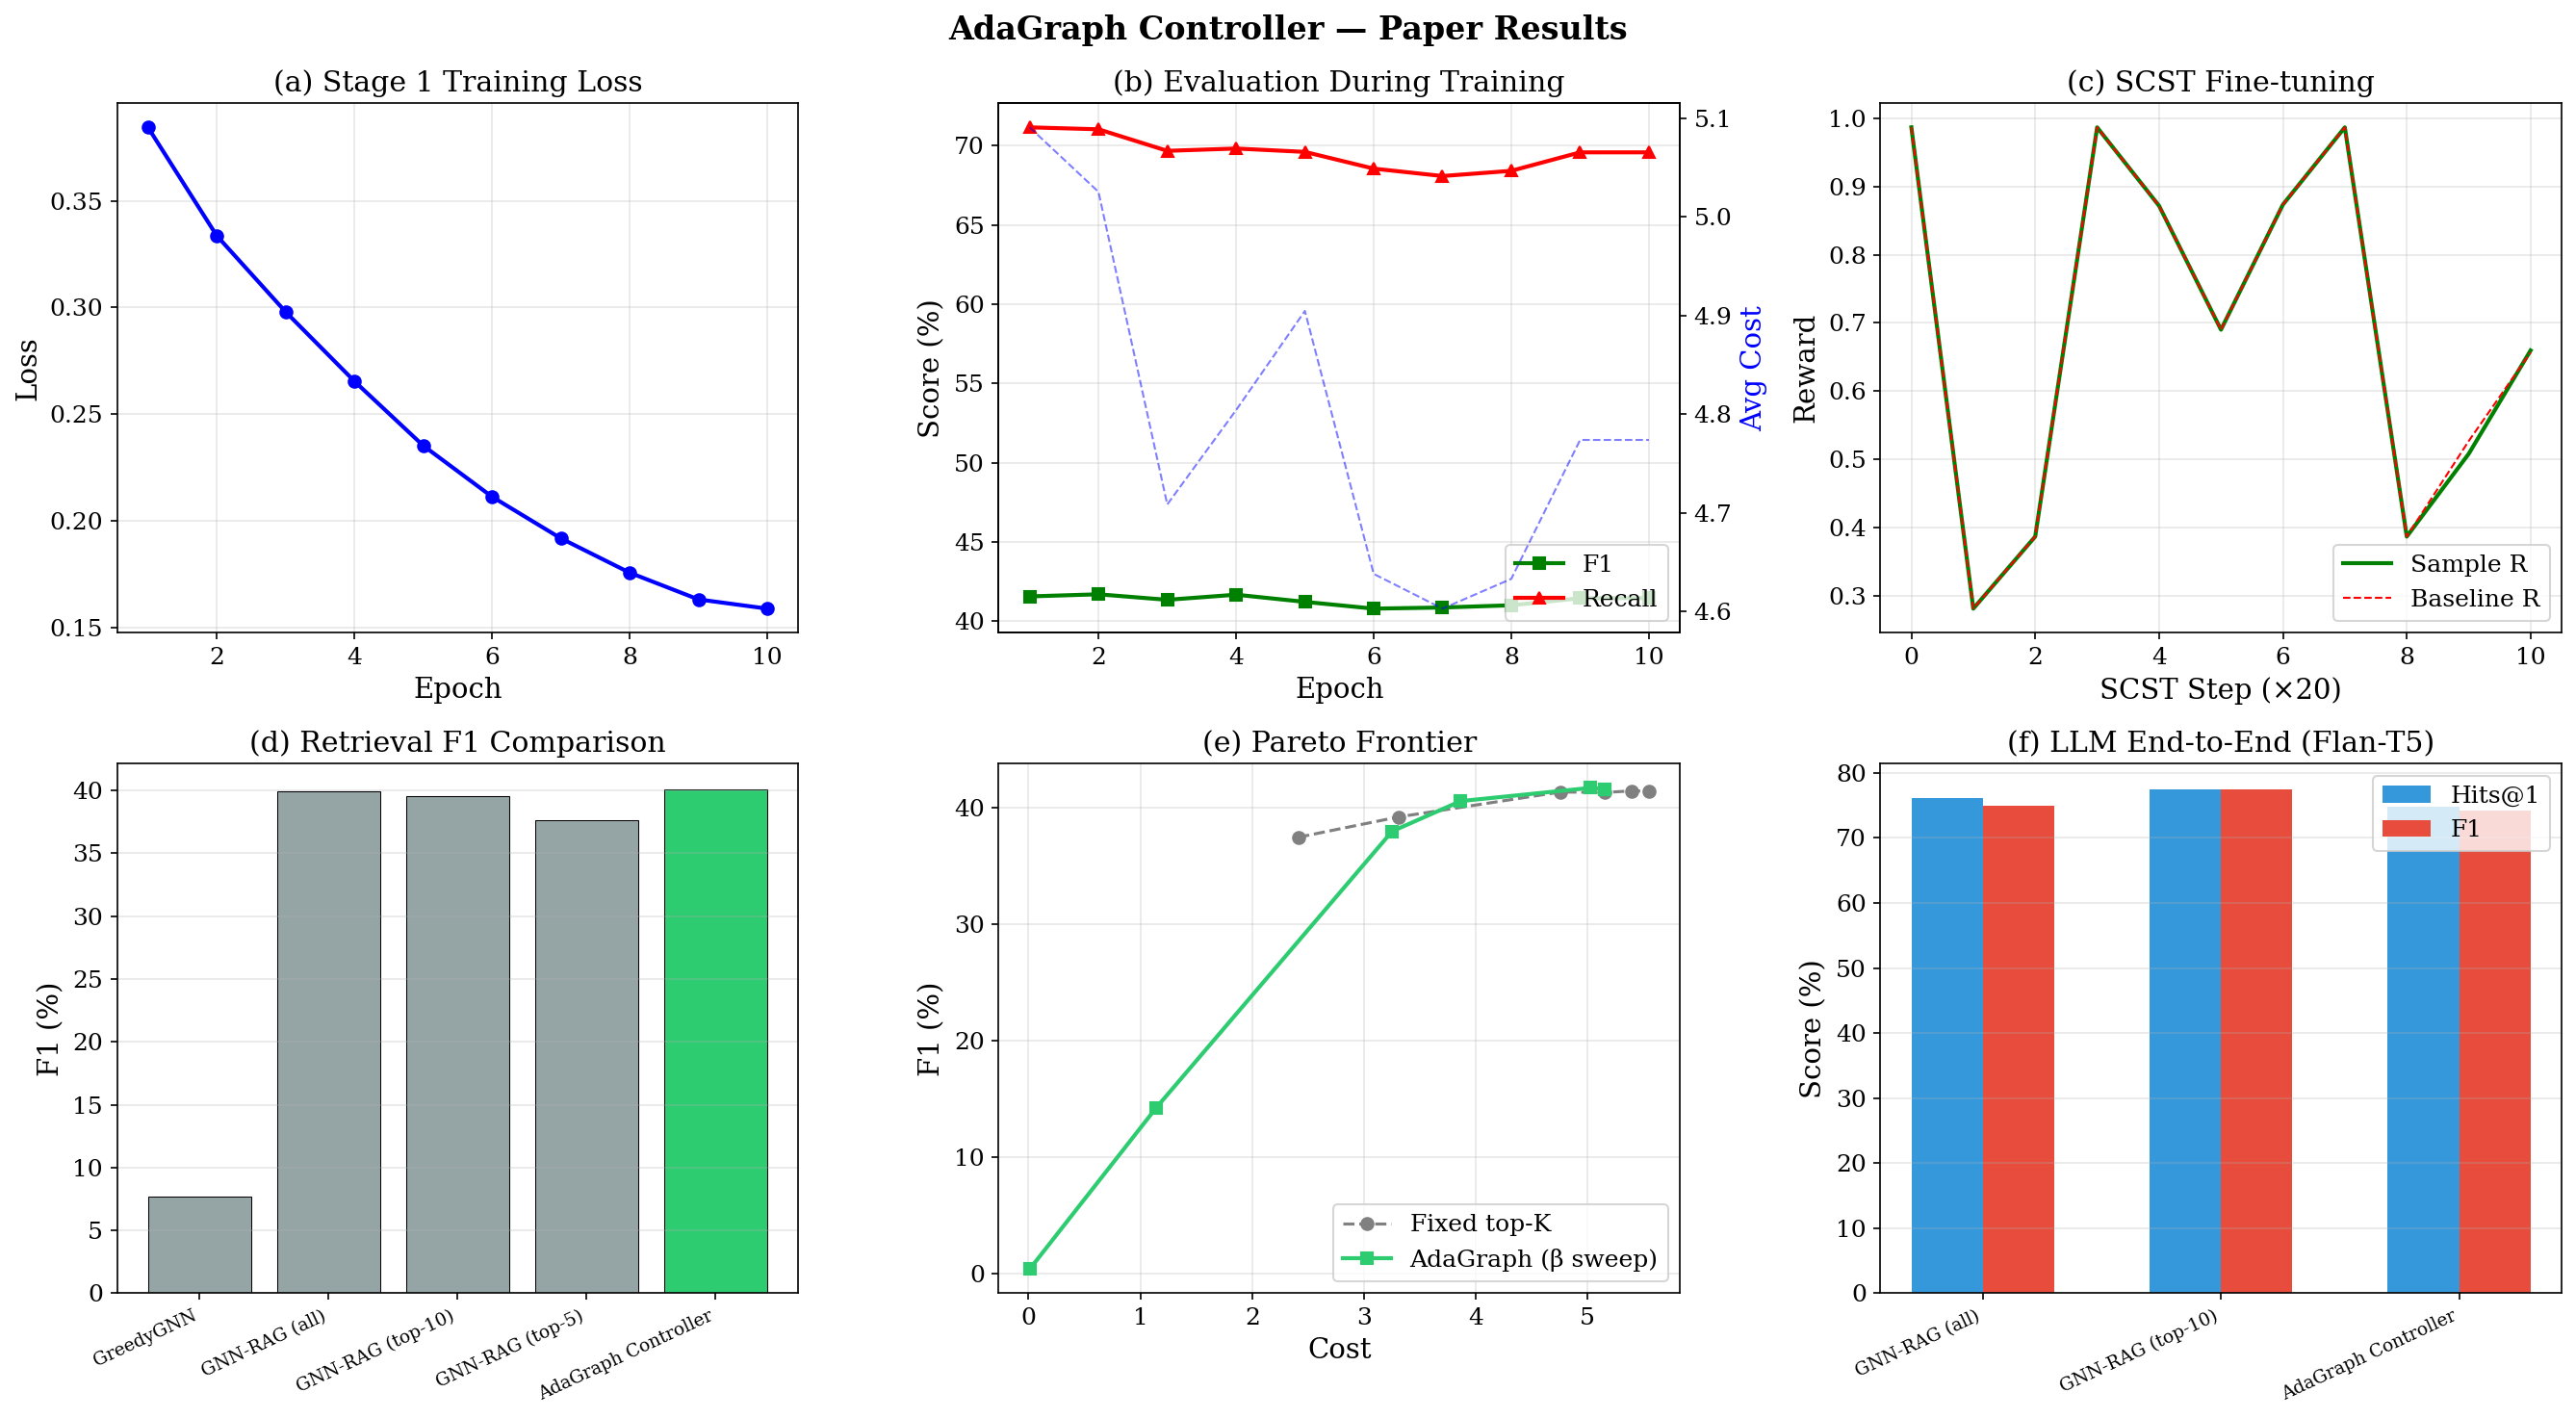

[OK] Paper figures saved


In [15]:
print("=" * 60)
print("PAPER FIGURES")
print("=" * 60)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('AdaGraph Controller — Paper Results', fontsize=16, fontweight='bold')

# Fig 1: Training loss curve
ax = axes[0, 0]
if s1_history:
    eps = [h['epoch'] for h in s1_history]
    ax.plot(eps, [h['loss'] for h in s1_history], 'b-o', lw=2)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.set_title('(a) Stage 1 Training Loss')
    ax.grid(True, alpha=0.3)

# Fig 2: Training eval metrics
ax = axes[0, 1]
if s1_history:
    ax.plot(eps, [h['eval_f1']*100 for h in s1_history], 'g-s', lw=2, label='F1')
    ax.plot(eps, [h['eval_recall']*100 for h in s1_history], 'r-^', lw=2, label='Recall')
    ax2 = ax.twinx()
    ax2.plot(eps, [h['eval_cost'] for h in s1_history], 'b--', lw=1, alpha=0.5, label='Cost')
    ax2.set_ylabel('Avg Cost', color='blue')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Score (%)')
    ax.set_title('(b) Evaluation During Training')
    ax.legend(loc='lower right'); ax.grid(True, alpha=0.3)

# Fig 3: SCST reward curve
ax = axes[0, 2]
if scst_history:
    steps = list(range(len(scst_history)))
    ax.plot(steps, [h['avg_reward'] for h in scst_history], 'g-', lw=2, label='Sample R')
    ax.plot(steps, [h['baseline'] for h in scst_history], 'r--', lw=1, label='Baseline R')
    ax.set_xlabel('SCST Step (×20)'); ax.set_ylabel('Reward')
    ax.set_title('(c) SCST Fine-tuning')
    ax.legend(); ax.grid(True, alpha=0.3)

# Fig 4: Method comparison bars
ax = axes[1, 0]
if all_results:
    names = list(all_results.keys())
    f1_vals = [all_results[n]['f1']*100 for n in names]
    colors = ['#95a5a6'] * (len(names)-1) + ['#2ecc71']
    ax.bar(range(len(names)), f1_vals, color=colors, edgecolor='black', linewidth=0.5)
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(names, rotation=25, ha='right', fontsize=9)
    ax.set_ylabel('F1 (%)')
    ax.set_title('(d) Retrieval F1 Comparison')
    ax.grid(True, alpha=0.3, axis='y')

# Fig 5: Pareto frontier (from earlier)
ax = axes[1, 1]
if fixed_results and beta_results:
    fk_c = [fixed_results[k]['cost'] for k in sorted(fixed_results)]
    fk_f = [fixed_results[k]['f1']*100 for k in sorted(fixed_results)]
    ax.plot(fk_c, fk_f, 'o--', color='gray', label='Fixed top-K')
    bc = [beta_results[b]['cost'] for b in betas]
    bf = [beta_results[b]['f1']*100 for b in betas]
    ax.plot(bc, bf, 's-', color='#2ecc71', lw=2, label='AdaGraph (β sweep)')
    ax.set_xlabel('Cost'); ax.set_ylabel('F1 (%)')
    ax.set_title('(e) Pareto Frontier')
    ax.legend(); ax.grid(True, alpha=0.3)

# Fig 6: LLM end-to-end
ax = axes[1, 2]
if llm_results:
    names = list(llm_results.keys())
    hit_vals = [llm_results[n]['hit'] for n in names]
    f1_vals = [llm_results[n]['f1'] for n in names]
    x = np.arange(len(names))
    ax.bar(x - 0.15, hit_vals, 0.3, label='Hits@1', color='#3498db')
    ax.bar(x + 0.15, f1_vals, 0.3, label='F1', color='#e74c3c')
    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=25, ha='right', fontsize=9)
    ax.set_ylabel('Score (%)')
    ax.set_title('(f) LLM End-to-End (Flan-T5)')
    ax.legend(); ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'adagraph_controller_paper_figures.png'), dpi=300, bbox_inches='tight')
plt.show()
print("[OK] Paper figures saved")

In [16]:
print("=" * 60)
print("SAVING ALL RESULTS")
print("=" * 60)

final_results = {
    'config': {
        'emb_dim': EMB_DIM, 'hidden_dim': HIDDEN_DIM,
        'max_rounds': MAX_ROUNDS, 'select_k': SELECT_K,
        'max_paths': MAX_PATHS, 'sprt_beta': SPRT_BETA,
        's1_epochs': S1_EPOCHS, 's2_steps': S2_STEPS,
    },
    's1_history': s1_history,
    'scst_history': scst_history,
    'retrieval_results': {k: {mk: float(mv) for mk, mv in v.items()}
                          for k, v in all_results.items()} if all_results else {},
    'llm_results': llm_results if llm_results else {},
}

with open(os.path.join(RESULTS_DIR, 'adagraph_controller_full_results.json'), 'w') as f:
    json.dump(final_results, f, indent=2)

# Save final checkpoint
torch.save({
    'model_state': controller.state_dict(),
    'config': final_results['config'],
}, os.path.join(CHECKPOINT_DIR, 'adagraph_controller_final.pt'))

embedder.save_cache(EMB_CACHE)

print(f"  Results: {RESULTS_DIR}/adagraph_controller_full_results.json")
print(f"  Model:   {CHECKPOINT_DIR}/adagraph_controller_final.pt")
print(f"  Cache:   {EMB_CACHE}")
print(f"\n[ALL DONE]")

SAVING ALL RESULTS
Saved 22355 embeddings to /content/drive/MyDrive/ThS/Research/research/COLAB/RUNNING/checkpoints/embeddings_cache.pkl
  Results: /content/drive/MyDrive/ThS/Research/research/COLAB/RUNNING/results/adagraph_controller_full_results.json
  Model:   /content/drive/MyDrive/ThS/Research/research/COLAB/RUNNING/checkpoints/adagraph_controller_final.pt
  Cache:   /content/drive/MyDrive/ThS/Research/research/COLAB/RUNNING/checkpoints/embeddings_cache.pkl

[ALL DONE]
